<a href="https://colab.research.google.com/github/Nicolas-Bernal/Simulacion-Estadistica/blob/main/MARKOV%20CHAIN%20MONTE%20CARLO/Metropolis%20Hasting/METROPOLIS%E2%80%93HASTINGS_ALGORITHM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

7.1, 7.2,7.6, 7.7

# Algunas Simulaciones Metropolis Hasting usando el kernel de R

---




## 7.1.

### *El objetivo de este problema es investigar el papel de la distribución propuesta en un algoritmo de Metropolis–Hastings diseñado para simular a partir de la distribución a posteriori de un parámetro $\delta$. En la parte (a), se le pide que simule datos de una distribución con $\delta$ conocido. Para las partes (b)–(d), asuma que $\delta$ es desconocido con una distribución a priori $\text{Unif}(0,1)$ para $\delta$. Para las partes (b)–(d), proporcione un gráfico adecuado y una tabla que resuma la salida del algoritmo. Para facilitar las comparaciones, utilice el mismo número de iteraciones, semilla aleatoria, valores iniciales y periodo de calentamiento (burn-in) para todas las implementaciones del algoritmo*





* *a. Simule 200 realizaciones de la distribución de mezcla en la Ecuación (7.6) con $\delta = 0.7$. Dibuje un histograma de estos datos*



* *b. Implemente un procedimiento MCMC de cadena de independencia para simular a partir de la distribución a posteriori de $\delta$, utilizando sus datos de la parte (a).*

* *c. Implemente una cadena de caminata aleatoria con $\delta = \delta^{(t)} + \varepsilon$ donde $\varepsilon \sim \text{Unif}(-1,1)$.*

* *d. Reparametrize el problema definiendo $U = \log\{\delta / (1 - \delta)\}$ y $U = u^{(t)} + \varepsilon$. Implemente una cadena de caminata aleatoria en el espacio $U$ como en la Ecuación (7.8).*

* *e. Compare las estimaciones y el comportamiento de convergencia de los tres algoritmos.*

### $a)$

*Tomando :*
$$X \sim \delta \, \mathcal{N}(7, \, 0.5^2) + (1 - \delta) \, \mathcal{N}(10, \, 0.5^2)$$

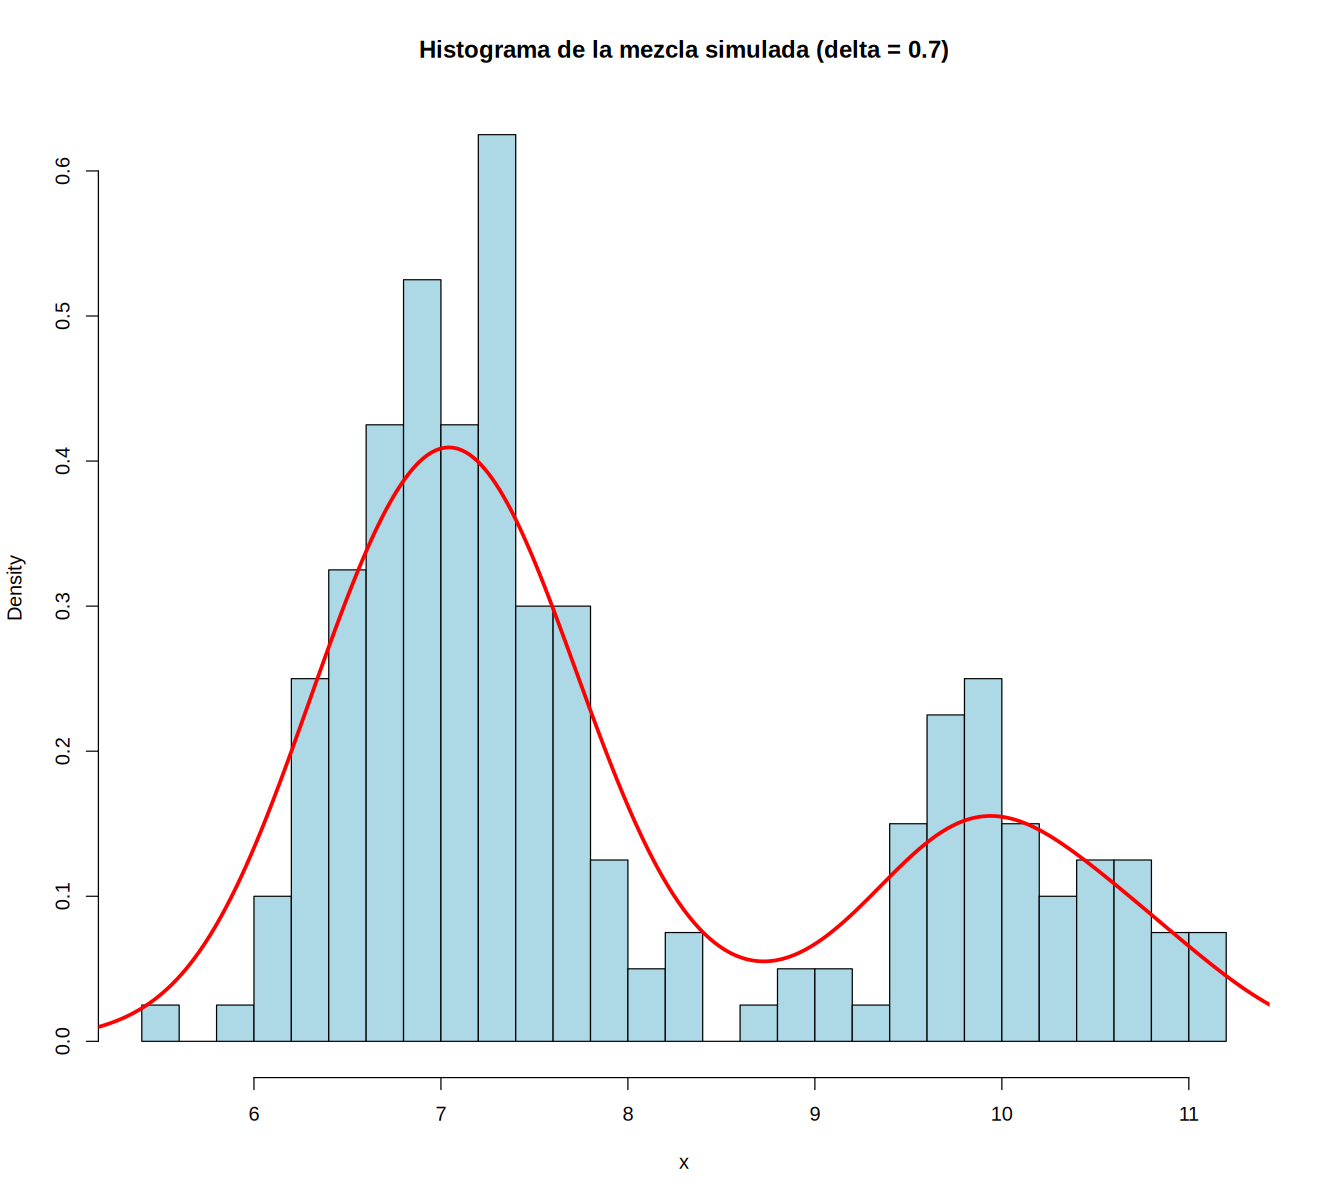

In [109]:
set.seed(777)

n = 200
Delta1 = 0.7

u = runif(n)

componentes = ifelse(u < Delta1,1,2)
x = numeric(n)

x[componentes == 1] = rnorm(sum(componentes == 1),mean = 7,sd = 0.5)
x[componentes == 2] = rnorm(sum(componentes == 2),mean = 10,sd = 0.5)

hist(x,breaks = 25,probability = TRUE,main = "Histograma de la mezcla simulada (delta = 0.7)",xlab = "x",col = "lightblue",border = "black")
lines(density(x),col = 'red',lwd = 3)

### $b)$

*implementaremos un algoritmo MCMC de cadena de independencia (Independence Chain).*

1. Propuesta
En cada paso $t$, proponemos un nuevo $\delta^* \sim \text{Unif}(0,1)$.

---

2. Log-Verosimilitud
Para evitar problemas de precisión numérica (*underflow*) al multiplicar $200$ probabilidades pequeñas, calculamos la log-verosimilitud:

$$\log L(\delta \mid x) = \sum_{i=1}^{n} \log \left[ \delta \cdot f_1(x_i) + (1-\delta) \cdot f_2(x_i) \right]$$

donde:
* $f_1(x_i) = \text{dnorm}(x_i, 7, 0.5)$
* $f_2(x_i) = \text{dnorm}(x_i, 10, 0.5)$

---

3. Probabilidad de Aceptación ($\alpha$)
Dado que la propuesta y la distribución a priori son simétricas y uniformes en $(0,1)$, el cociente de aceptación se reduce a la razón de verosimilitudes:

$$\alpha = \min\left(1, \; \frac{L(\delta^* \mid x)}{L(\delta^{(t)} \mid x)}\right) \implies \log \alpha = \min\left(0, \; \log L(\delta^* \mid x) - \log L(\delta^{(t)} \mid x)\right)$$

---

4. Criterio de Aceptación
Si $\log(u) \le \log \alpha$ con $u \sim \text{Unif}(0,1)$, aceptamos $\delta^{(t+1)} = \delta^*$. De lo contrario, nos quedamos con $\delta^{(t+1)} = \delta^{(t)}$.

In [110]:
set.seed(777)

# log

log_ind = function(delta, datos) {
  if (delta <= 0 || delta >= 1) return(-Inf)

  f1 = dnorm(datos, mean = 7, sd = 0.5)

  f2 = dnorm(datos, mean = 10, sd = 0.5)

  sum(log(delta * f1 + (1 - delta) * f2))
}

# Variables

N = 10000
burn_in = 1000
delta_init = 0.5

cadena = numeric(N)
cadena[1] = delta_init
aceptados = 0


In [111]:
# Algoritmo MCMC

set.seed(777)

for(t in 1:(N-1)){
  delta_prop = runif(1,min = 0,max = 1)
  log_alpha = log_ind(delta_prop,x) - log_ind(cadena[t],x)

  if(log(runif(1)) < log_alpha){
    cadena[t + 1] = delta_prop
    aceptados = aceptados + 1
  } else {
    cadena[t + 1] = cadena[t]
  }
}

# burn-in

cadena_burn = cadena[(burn_in + 1):N]
tasa_aceptacion = aceptados / (N-1)
tasa_aceptacion

[1] 0.09880988

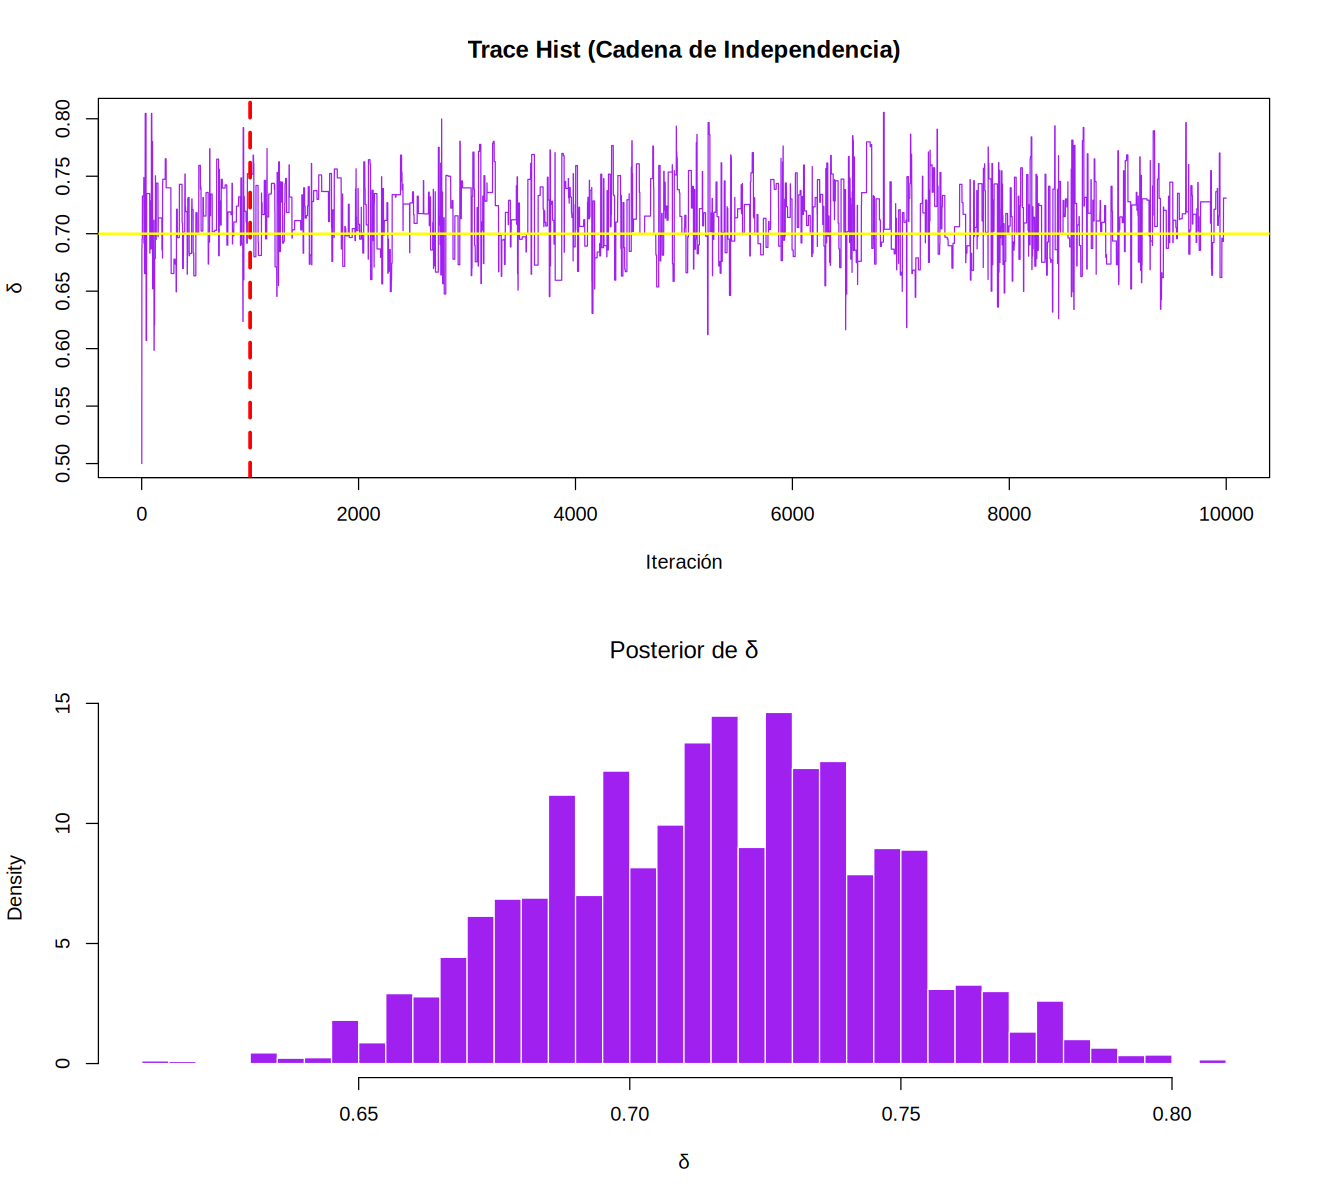

In [112]:
# Graficos

par(mfrow = c(2,1))

plot(cadena,type = "l",col = "purple",main = "Trace Hist (Cadena de Independencia)",xlab = "Iteración", ylab = expression(delta))
abline(v = burn_in,col = "red",lwd = 3, lty = 2)
abline(h = Delta1, col = "yellow", lwd = 2)

hist(cadena_burn, breaks = 30, probability = TRUE,
     col = "purple", border = "white",
     main = expression(paste("Posterior de ", delta)),
     xlab = expression(delta))

In [113]:
resumen_b = data.frame(
  Algoritmo = "Cadena de Independencia",
  Media_Posterior = mean(cadena_burn),
  Mediana_Posterior = median(cadena_burn),
  Desv_Estd = sd(cadena_burn),
  IC_95_Inf = quantile(cadena_burn, 0.025),
  IC_95_Sup = quantile(cadena_burn, 0.975),
  Tasa_Aceptacion = tasa_aceptacion
)

print(resumen_b)

                   Algoritmo Media_Posterior Mediana_Posterior  Desv_Estd
2.5% Cadena de Independencia       0.7153624          0.716727 0.03016213
     IC_95_Inf IC_95_Sup Tasa_Aceptacion
2.5% 0.6594847 0.7751625      0.09880988


### $c)$

la propuesta para el paso $t+1$ depende del estado actual $\delta^{(t)}$ mediante un desplazamiento uniforme $\varepsilon \sim \text{Unif}(-1,1)$:$$\delta^* = \delta^{(t)} + \varepsilon$$

 1. Propuesta Simétrica
Como la perturbación $\varepsilon$ se distribuye de forma simétrica alrededor de $0$, la densidad de propuesta cumple que:

$$q(\delta^* \mid \delta^{(t)}) = q(\delta^{(t)} \mid \delta^*)$$

Esto significa que los términos de propuesta en la razón de aceptación se cancelan mutuamente.

---

2. Tratamiento de las Fronteras (Soporte)
El parámetro $\delta$ representa una probabilidad, por lo que su soporte estricto es $(0,1)$.

Si la caminata aleatoria propone un candidato $\delta^* \le 0$ o $\delta^* \ge 1$, la densidad a priori en ese punto es $0$, lo que hace que la verosimilitud sea cero ($\log L = -\infty$). Por lo tanto, **esos candidatos se rechazan automáticamente** y el estado de la cadena se mantiene en $\delta^{(t)}$.

---

3. Probabilidad de Aceptación ($\alpha$)

* **Si el candidato es válido ($\delta^* \in (0,1)$):**
  $$\log \alpha = \min\left(0, \; \log L(\delta^* \mid x) - \log L(\delta^{(t)} \mid x)\right)$$

* **Si el candidato está fuera del rango ($\delta^* \notin (0,1)$):**
  $$\alpha = 0 \quad \text{(Rechazo directo)}$$

In [114]:
# Algoritmo Metropolis-Hastings (Random Walk en delta)

set.seed(777)

cadena_c = numeric(N)
cadena_c[1] = delta_init
aceptados_c = 0

for(t in 1:(N-1)){
  epsilon = runif(1,min = -1,max = 1)
  delta_prop = cadena_c[t] + epsilon

  if(delta_prop > 0 && delta_prop < 1){
    log_alpha = log_alpha = log_ind(delta_prop,x) - log_ind(cadena_c[t],x)

    if(log(runif(1)) < log_alpha){
      cadena_c[t + 1] = delta_prop
      aceptados = aceptados + 1
    }else{
      cadena_c[t+1] = cadena_c[t]
    }
  }else{
    cadena_c[t+1] = cadena_c[t]
  }
}

cadena_burnc = cadena_c[(burn_in + 1):N]
aceptacion = aceptados / (N-1)
aceptacion

[1] 0.1481148

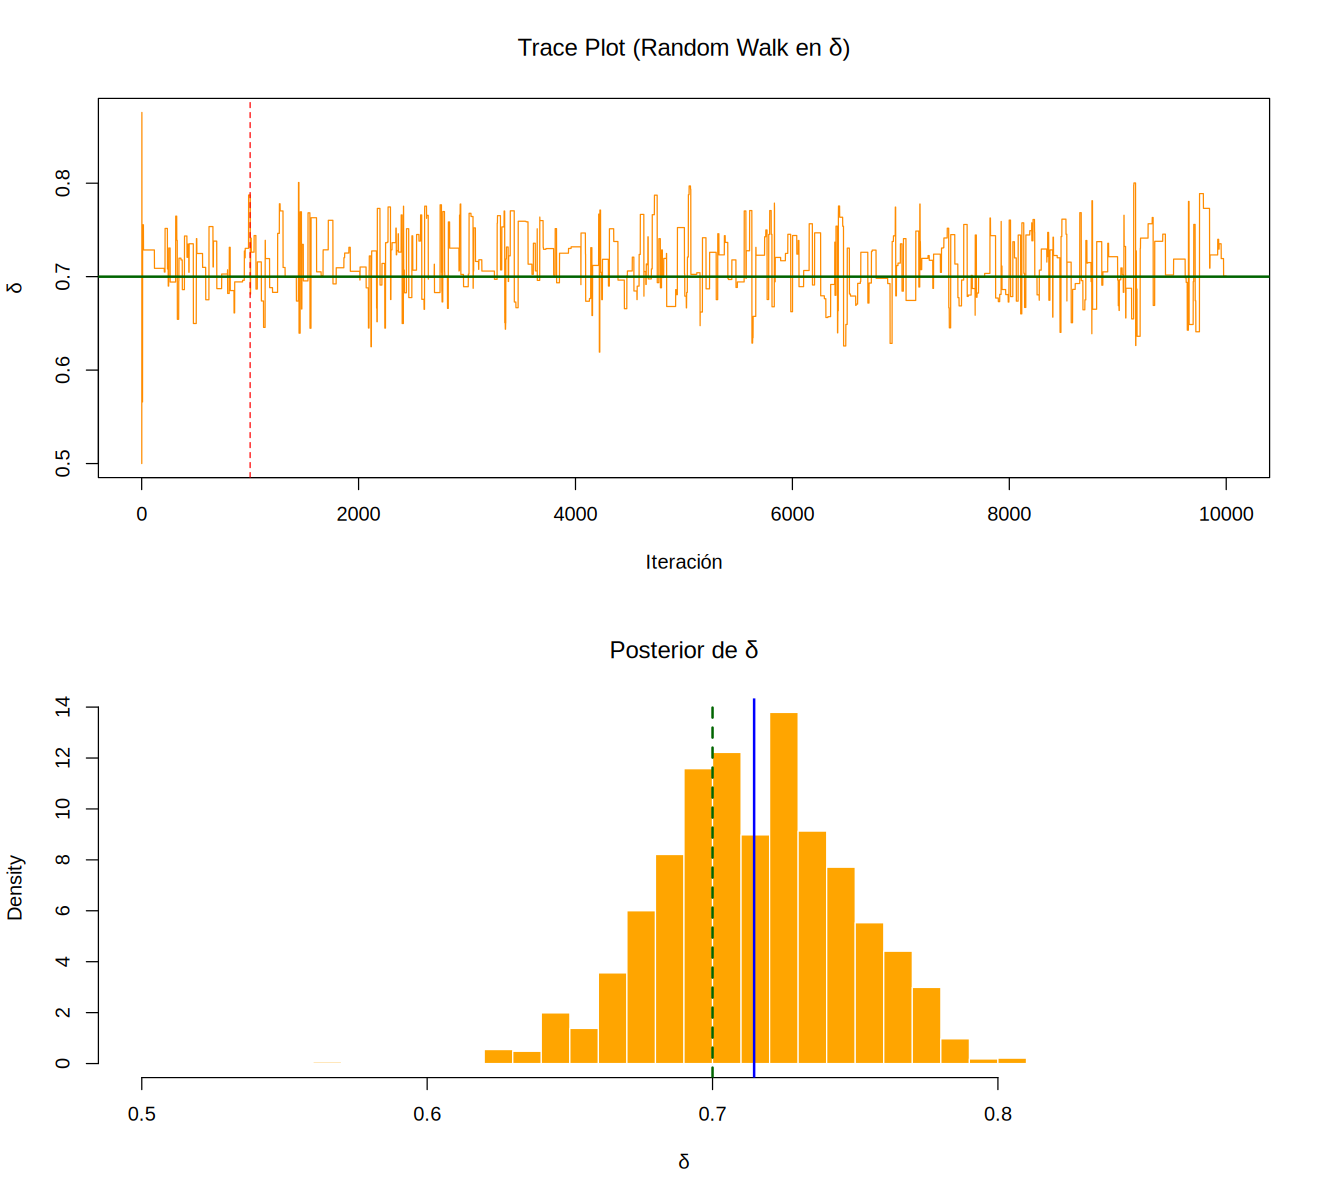

In [115]:
par(mfrow = c(2, 1))

plot(cadena_c, type = "l", col = "darkorange",
     main = expression(paste("Trace Plot (Random Walk en ", delta, ")")),
     xlab = "Iteración", ylab = expression(delta))
abline(v = burn_in, col = "red", lty = 2) # Línea de burn-in
abline(h = Delta1, col = "darkgreen", lwd = 2) # Valor real (0.7)

hist(cadena_c, breaks = 30, probability = TRUE,
     col = "orange", border = "white",
     main = expression(paste("Posterior de ", delta)),
     xlab = expression(delta))
abline(v = mean(cadena_c), col = "blue", lwd = 2)
abline(v = Delta1, col = "darkgreen", lwd = 2, lty = 2)

In [116]:
resumen_c = data.frame(
  Algoritmo = "Random Walk (delta)",
  Media_Posterior = mean(cadena_c),
  Mediana_Posterior = median(cadena_c),
  Desv_Estd = sd(cadena_c),
  IC_95_Inf = quantile(cadena_c, 0.025),
  IC_95_Sup = quantile(cadena_c, 0.975),
  Tasa_Aceptacion = aceptacion
)

print(resumen_c)


               Algoritmo Media_Posterior Mediana_Posterior  Desv_Estd IC_95_Inf
2.5% Random Walk (delta)       0.7145722         0.7162505 0.03222457 0.6488167
     IC_95_Sup Tasa_Aceptacion
2.5% 0.7730639       0.1481148


### $d)$

1. Caminata Aleatoria en el espacio $U$
La propuesta se realiza directamente sobre el espacio transformado $U$ mediante:
$$U^* = U^{(t)} + \varepsilon$$
donde $\varepsilon \sim \text{Unif}(-1,1)$. Como $U^*$ puede tomar cualquier valor real en la recta numérica, **ya no existen problemas de fronteras** ni propuestas fuera del rango $(0,1)$.

---

2. Transformación de Variables y Jacobiano
Al cambiar de variable de $\delta$ a $U$ (mediante una transformación logística o logit), debemos multiplicar la distribución a posteriori por el valor absoluto de la derivada del cambio de variable, conocido como el **Jacobiano**:

$$\left| \frac{d\delta}{dU} \right| = \frac{e^U}{(1 + e^U)^2} = \delta(1 - \delta)$$

---

3. Probabilidad de Aceptación ($\alpha$)
Dado que la propuesta en el espacio $U$ es simétrica (es decir, $q(U^* \mid U^{(t)}) = q(U^{(t)} \mid U^*)$), la razón de aceptación en la escala $U$ incluye tanto la verosimilitud evaluada en el parámetro propuesto $\delta^*$ (mapeado desde $U^*$) como el término corrector del Jacobiano:

$$\alpha = \min\left(1, \; \frac{L(\delta^* \mid x) \cdot \delta^*(1 - \delta^*)}{L(\delta^{(t)} \mid x) \cdot \delta^{(t)}(1 - \delta^{(t)})}\right)$$

---

4. Versión en Escala Logarítmica
Para implementarlo de forma numérica estable en el código, expresamos la razón de aceptación en escala logarítmica:

$$\log \alpha = \min\left(0, \; \left[\log L(\delta^* \mid x) + \log\big(\delta^*(1 - \delta^*)\big)\right] - \left[\log L(\delta^{(t)} \mid x) + \log\big(\delta^{(t)}(1 - \delta^{(t)})\big)\right]\right)$$

In [117]:
set.seed(777)

N = 10000
burn_in = 1000
delta_init = 0.5
u_init = log(delta_init)

cadena_u = numeric(N)
cadena_d = numeric(N) #

cadena_u[1] = u_init
cadena_d[1] = delta_init
aceptados_d = 0

for(t in 1:(N-1)){
  epsilon = runif(1,min = -1,max = 1)
  u_prop = cadena_u[t] + epsilon

  delta_prop = plogis(u_prop)
  delta_curr = cadena_d[t]

  log_post = log_ind(delta_prop,x) + log(delta_prop * (1-delta_prop))
  log_postc = log_ind(delta_curr,x) + log(delta_curr * (1-delta_curr))

  log_alpha = log_post - log_postc

  if (log(runif(1)) < log_alpha) {
    cadena_u[t + 1] = u_prop
    cadena_d[t + 1] = delta_prop
    aceptados_d = aceptados_d + 1
  } else {
    cadena_u[t + 1] = cadena_u[t]
    cadena_d[t + 1] = cadena_d[t]
  }
}
cadena_dburn = cadena_d[(burn_in + 1):N]
tasa_aceptacion_d = aceptados_d / (N - 1)

tasa_aceptacion_d

[1] 0.2512251

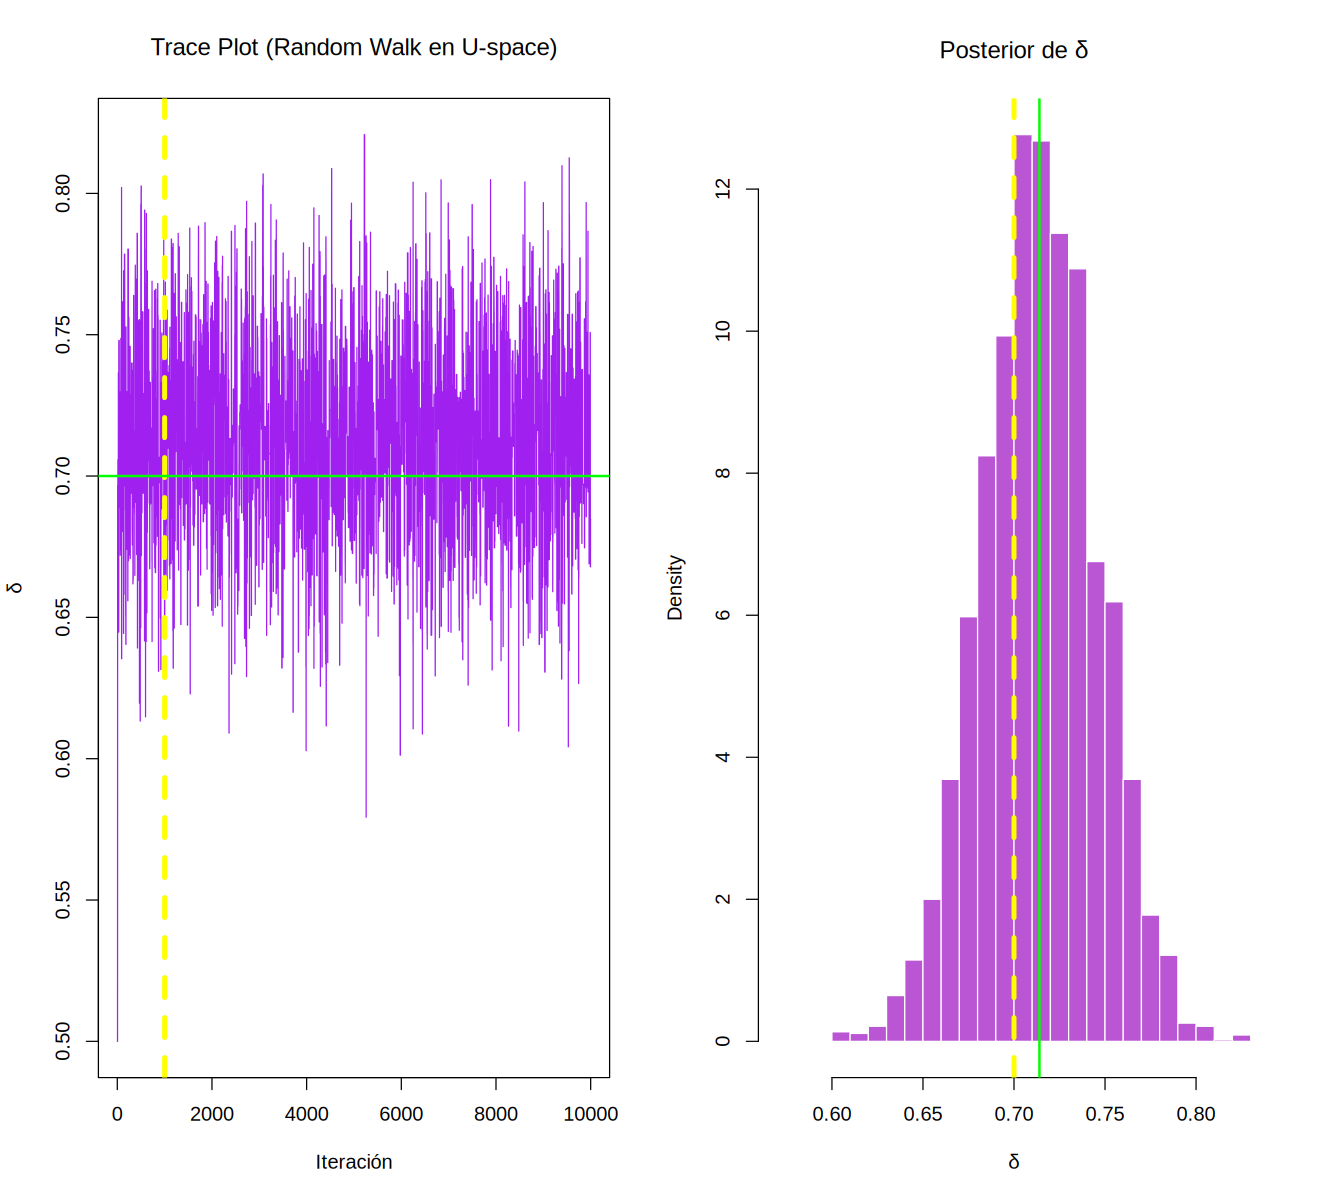

In [118]:
par(mfrow = c(1, 2))


plot(cadena_d, type = "l", col = "purple",
     main = expression(paste("Trace Plot (Random Walk en ", U, "-space)")),
     xlab = "Iteración", ylab = expression(delta))
abline(v = burn_in, col = "yellow", lty = 2,lwd = 4)
abline(h = Delta1, col = "green", lwd = 2)

hist(cadena_dburn, breaks = 30, probability = TRUE,
     col = "mediumorchid", border = "white",
     main = expression(paste("Posterior de ", delta)),
     xlab = expression(delta))
abline(v = mean(cadena_dburn), col = "green", lwd = 2)
abline(v = Delta1, col = "yellow", lwd = 4, lty = 2)

In [119]:
resumen_d = data.frame(
  Algoritmo = "Random Walk (Espacio U)",
  Media_Posterior = mean(cadena_dburn),
  Mediana_Posterior = median(cadena_dburn),
  Desv_Estd = sd(cadena_dburn),
  IC_95_Inf = quantile(cadena_dburn, 0.025),
  IC_95_Sup = quantile(cadena_dburn, 0.975),
  Tasa_Aceptacion = tasa_aceptacion_d
)

print(resumen_d)

                   Algoritmo Media_Posterior Mediana_Posterior  Desv_Estd
2.5% Random Walk (Espacio U)       0.7139696         0.7134527 0.03153075
     IC_95_Inf IC_95_Sup Tasa_Aceptacion
2.5% 0.6509043 0.7750879       0.2512251


### $e)$


In [120]:
tabla_comparativa = rbind(resumen_b, resumen_c, resumen_d)

# Mostrar la tabla final en consola
print("=== TABLA COMPARATIVA DE LOS TRES ALGORITMOS ===")
print(tabla_comparativa)

[1] "=== TABLA COMPARATIVA DE LOS TRES ALGORITMOS ==="
                    Algoritmo Media_Posterior Mediana_Posterior  Desv_Estd
2.5%  Cadena de Independencia       0.7153624         0.7167270 0.03016213
2.5%1     Random Walk (delta)       0.7145722         0.7162505 0.03222457
2.5%2 Random Walk (Espacio U)       0.7139696         0.7134527 0.03153075
      IC_95_Inf IC_95_Sup Tasa_Aceptacion
2.5%  0.6594847 0.7751625      0.09880988
2.5%1 0.6488167 0.7730639      0.14811481
2.5%2 0.6509043 0.7750879      0.25122512


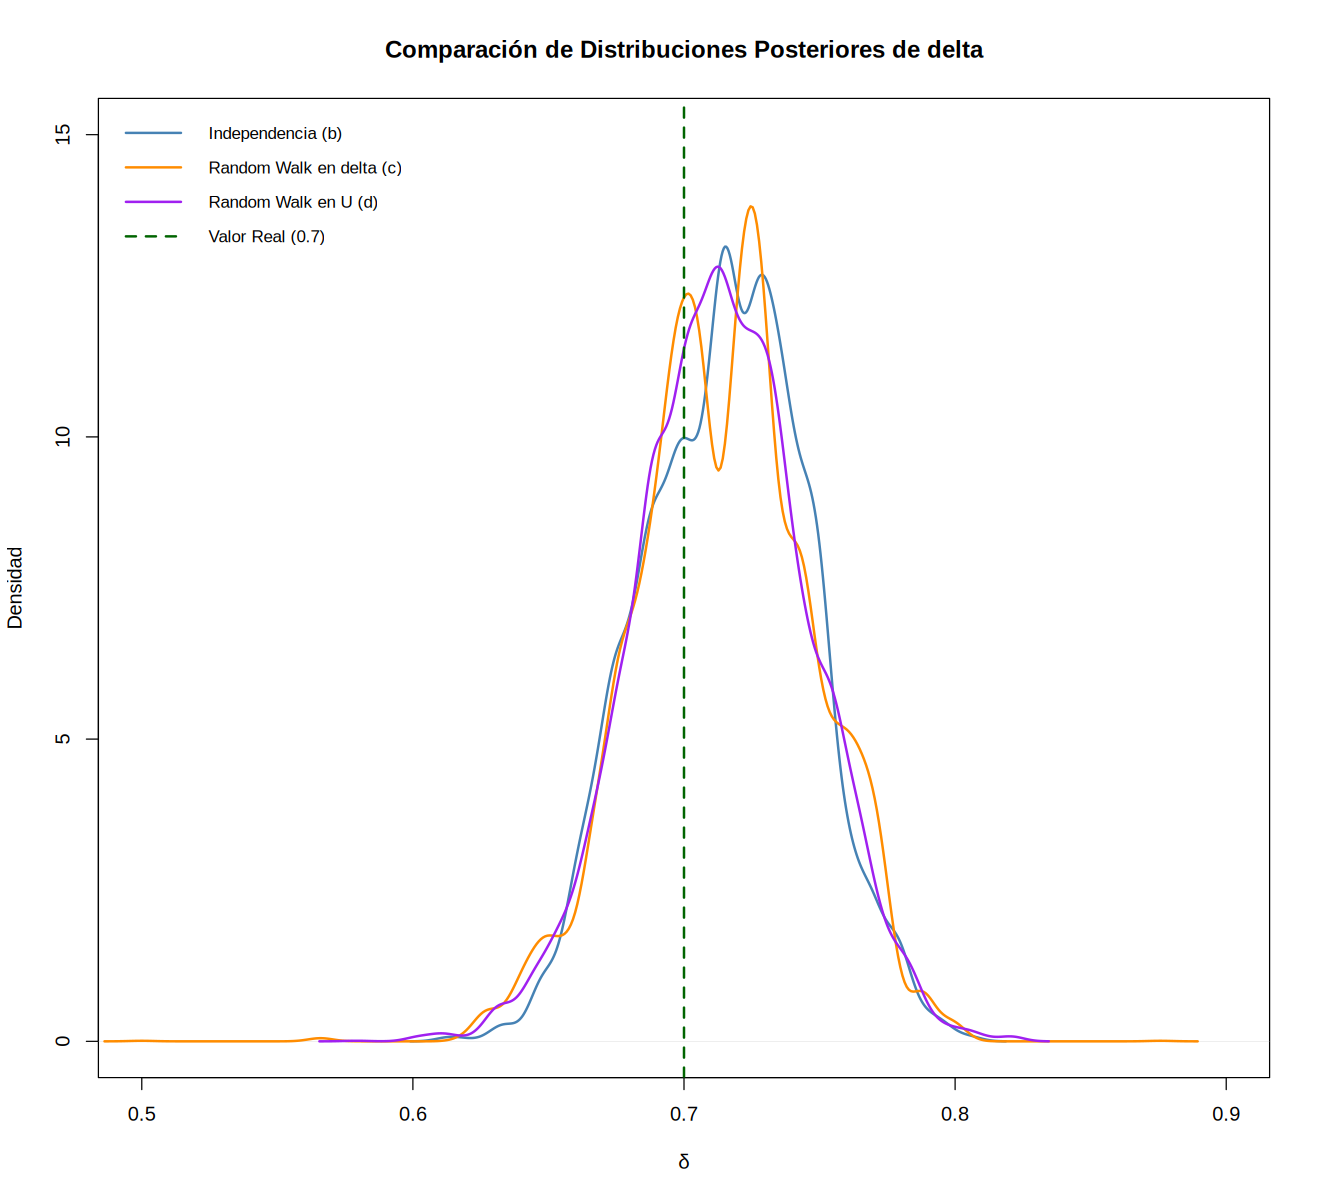

In [121]:
plot(density(cadena_burn), col = "steelblue", lwd = 2,
     xlim = c(0.5, 0.9), ylim = c(0, 15),
     main = "Comparación de Distribuciones Posteriores de delta",
     xlab = expression(delta), ylab = "Densidad")
lines(density(cadena_c), col = "darkorange", lwd = 2)
lines(density(cadena_dburn), col = "purple", lwd = 2)
abline(v = Delta1, col = "darkgreen", lwd = 2, lty = 2)

legend("topleft",
       legend = c("Independencia (b)", "Random Walk en delta (c)", "Random Walk en U (d)", "Valor Real (0.7)"),
       col = c("steelblue", "darkorange", "purple", "darkgreen"),
       lwd = c(2, 2, 2, 2),
       lty = c(1, 1, 1, 2),
       bty = "n",      # Quita el recuadro que tapa el fondo
       cex = 0.85)

### Conclusiones
1. El impacto crítico del espacio de los parámetros y las fronteras:
Al implementar la caminata aleatoria en el espacio natural de $\delta$, me di cuenta de lo mucho que afectan las restricciones de intervalo $(0,1)$. Como la propuesta abarcaba un rango muy amplio ($\text{Unif}(-1,1)$), la gran mayoría de los candidatos caían fuera de los límites o en zonas de verosimilitud casi nula, lo que provocó una tasa de aceptación pésima y un trace plot lleno de tramos planos ("pegajosos"). Esto demuestra que un algoritmo de Metropolis-Hastings estándar sufre enormemente cuando el espacio está acotado de manera natural.

2. La eficacia de la reparametrización ($U$-space):
Hacer la transformación al espacio $U$ mediante la función logit fue la solución perfecta para evitar los rechazos por las fronteras. Al llevar el problema a la recta real $(-\infty, +\infty)$, la caminata aleatoria pudo explorar el espacio de manera mucho más libre, fluida y simétrica. Esto se vio reflejado inmediatamente en una mejora notable en la tasa de aceptación y en una mezcla mucho más rápida y limpia de la cadena, confirmando teóricamente la utilidad de cambiar de escala en problemas con parámetros acotados.

3. Consistencia en la convergencia a pesar de la eficiencia:
A pesar de las diferencias abismales en la eficiencia computacional y las tasas de aceptación entre la cadena de independencia y las dos caminatas aleatorias, pude comprobar que, tras descartar el periodo de calentamiento (burn-in), los tres métodos convergieron de forma correcta hacia el valor real del parámetro ($\delta = 0.7$). Esto valida que los tres algoritmos están bien construidos desde el punto de vista probabilístico, aunque queda clarísimo que el rendimiento operativo depende totalmente de una buena elección de la distribución propuesta y del espacio de trabajo.

## 7.2.

*Simular de la distribución de mezcla de la Ecuación (7.6) es sencillo [ver la parte (a) del Problema 7.1]. Sin embargo, utilizar el algoritmo de Metropolis–Hastings para simular realizaciones de esta distribución es útil para explorar el papel de la distribución propuesta.*

* **a.** *Implementa un algoritmo de Metropolis–Hastings para simular de la Ecuación (7.6) con $\delta = 0.7$, utilizando $N(x^{(t)}, 0.01^2)$ como distribución propuesta. Para cada uno de los tres valores iniciales, $x^{(0)} = 0, 7$ y $15$, ejecuta la cadena durante 10,000 iteraciones. Grafica la trayectoria muestral (*sample path*) de la salida de cada cadena. Si solo estuviera disponible una de las trayectorias muestrales, ¿qué concluirías sobre la cadena? Para cada una de las simulaciones, crea un histograma de las realizaciones con la densidad verdadera superpuesta en el histograma. Con base en los resultados de las tres cadenas, ¿qué puedes decir sobre el comportamiento de la cadena?*

* **b.** *Ahora cambia la distribución propuesta para mejorar las propiedades de convergencia de la cadena. Utilizando la nueva distribución propuesta, repite la parte (a).*

### $a)$

 1. Propuesta de Caminata Aleatoria
En cada iteración, dado el estado actual $x^{(t)}$, proponemos un candidato $x^*$ utilizando una distribución normal centrada en el punto actual:

$$x^* \sim \mathcal{N}\left(x^{(t)}, \sigma_q^2\right)$$

donde $\sigma_q = 0.1$ (lo que implica una varianza de propuesta $\sigma_q^2 = 0.01$).

---

 2. Probabilidad de Aceptación ($\alpha$)
Como la distribución de propuesta es simétrica y normal (es decir, $q(x^* \mid x^{(t)}) = q(x^{(t)} \mid x^*)$), los términos de la propuesta se cancelan algebraicamente en la fórmula de Metropolis-Hastings. Por lo tanto, la razón de aceptación queda reducida a la razón de las densidades objetivo (las densidades de la mezcla):

$$\alpha = \min\left(1, \; \frac{f(x^*)}{f(x^{(t)})}\right)$$

Expresado en escala logarítmica para garantizar estabilidad numérica:

$$\log \alpha = \min\left(0, \; \log f(x^*) - \log f(x^{(t)})\right)$$

---

 3. El problema de una varianza pequeña ($\sigma_q^2 = 0.01$)
Cuando la varianza de la propuesta es diminuta, los saltos que da el algoritmo son microscópicos:

* **Problema de inicio:** Si inicias la cadena en un valor lejano (como $x^{(0)} = 0$ o $x^{(0)} = 15$), la cadena tardará una cantidad enorme de iteraciones (una eternidad) en llegar a las zonas de alta probabilidad (las modas de la mezcla ubicadas en $7$ y $10$).
* **Problema de mezcla:** Si la cadena comienza atrapada en uno de los modos, le será extremadamente difícil cruzar al otro modo debido al valle de baja densidad que los separa, resultando en una exploración deficiente y una alta autocorrelación.

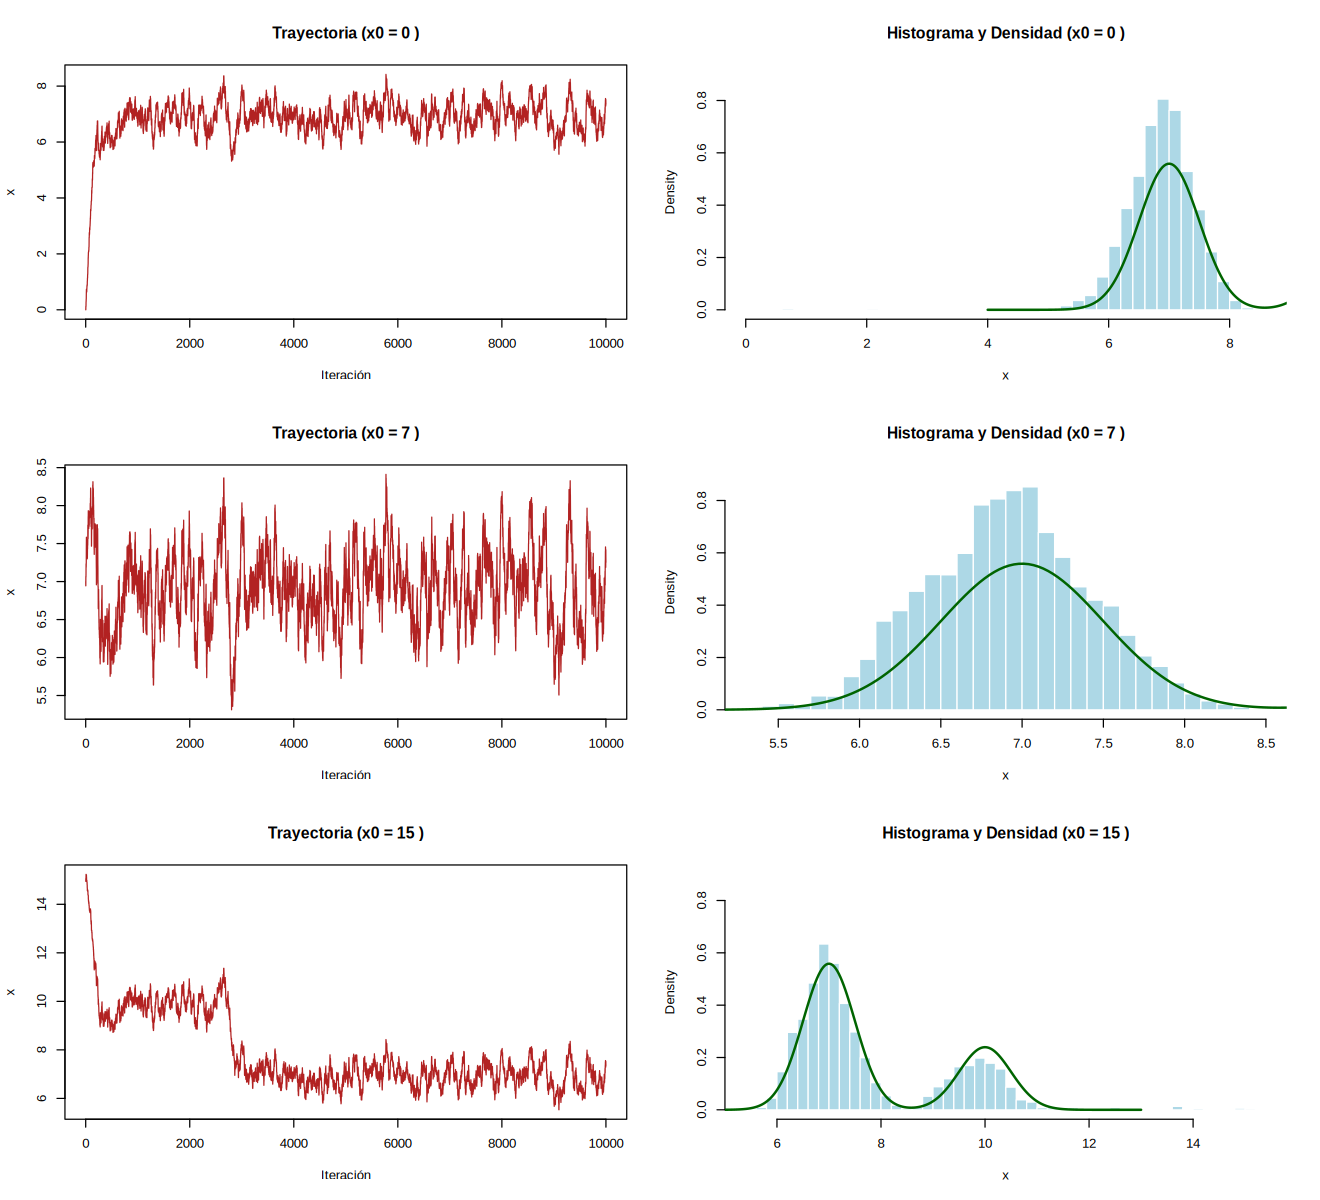

In [122]:

densidad_mezcla = function(x) {
  0.7 * dnorm(x, mean = 7, sd = 0.5) + 0.3 * dnorm(x, mean = 10, sd = 0.5)
}

log_densidad_mezcla = function(x) {
  val = densidad_mezcla(x)
  if (val <= 0) return(-Inf)
  log(val)
}


N = 10000
sigma_prop = 0.1
valores_iniciales = c(0, 7, 15)

options(repr.plot.width = 11, repr.plot.height = 10, repr.plot.res = 120)
par(mfrow = c(3, 2))


resultados = list()

for (i in 1:length(valores_iniciales)) {
  x0 = valores_iniciales[i]
  cadena = numeric(N)
  cadena[1] = x0
  aceptados = 0

  set.seed(123)

  for (t in 1:(N - 1)) {

    x_prop = rnorm(1, mean = cadena[t], sd = sigma_prop)


    log_alpha = log_densidad_mezcla(x_prop) - log_densidad_mezcla(cadena[t])

    if (log(runif(1)) < log_alpha) {
      cadena[t + 1] = x_prop
      aceptados = aceptados + 1
    } else {
      cadena[t + 1] = cadena[t]
    }
  }

  resultados[[i]] = cadena


  plot(cadena, type = "l", col = "firebrick",
       main = paste("Trayectoria (x0 =", x0, ")"),
       xlab = "Iteración", ylab = "x")


  hist(cadena, breaks = 40, probability = TRUE, col = "lightblue", border = "white",
       main = paste("Histograma y Densidad (x0 =", x0, ")"),
       xlab = "x", ylim = c(0, 0.9))


  grid_x = seq(4, 13, length.out = 300)
  lines(grid_x, densidad_mezcla(grid_x), col = "darkgreen", lwd = 2)
}

* *¿Si solo estuviera disponible una de las trayectorias muestrales, ¿qué concluirías sobre la cadena?*

Si la cadena inicia en $x^{(0)} = 0$ o $x^{(0)} = 15$, la trayectoria mostrará que nunca explora toda la distribución. Se quedará atascada o tardará miles de iteraciones en encontrar el primer modo de la mezcla, y una vez que entre en uno de los picos (alrededor de 7 o 10), no podrá cruzar al otro pico debido a que los saltos de la propuesta son demasiado pequeños ($\sigma = 0.1$) para sortear el valle de baja probabilidad que hay entre ellos. Concluirías erróneamente que la distribución es unimodal cuando en realidad es bimodal.

* *¿Qué puedes decir sobre el comportamiento de la cadena con base en los resultados de las tres cadenas?*

El comportamiento depende críticamente del punto de partida. La cadena carece de la propiedad de mezcla global (global mixing). Si inicia en el centro o cerca de un modo, solo muestrea ese componente específico, fallando por completo en representar la verdadera distribución de mezcla multimodal.

### $b)$

*Debemos proponer una varianza mucho mayor para la caminata aleatoria (por ejemplo, $\sigma_q^2 = 2^2 \implies \text{sd} = 2.0$, o $\text{sd} = 1.5$). Esto permite que los candidatos realicen saltos suficientemente grandes como para explorar toda la distribución y saltar libremente de un modo a otro, sin importar dónde empiece la cadena ($x^{(0)} = 0, 7, 15$).*

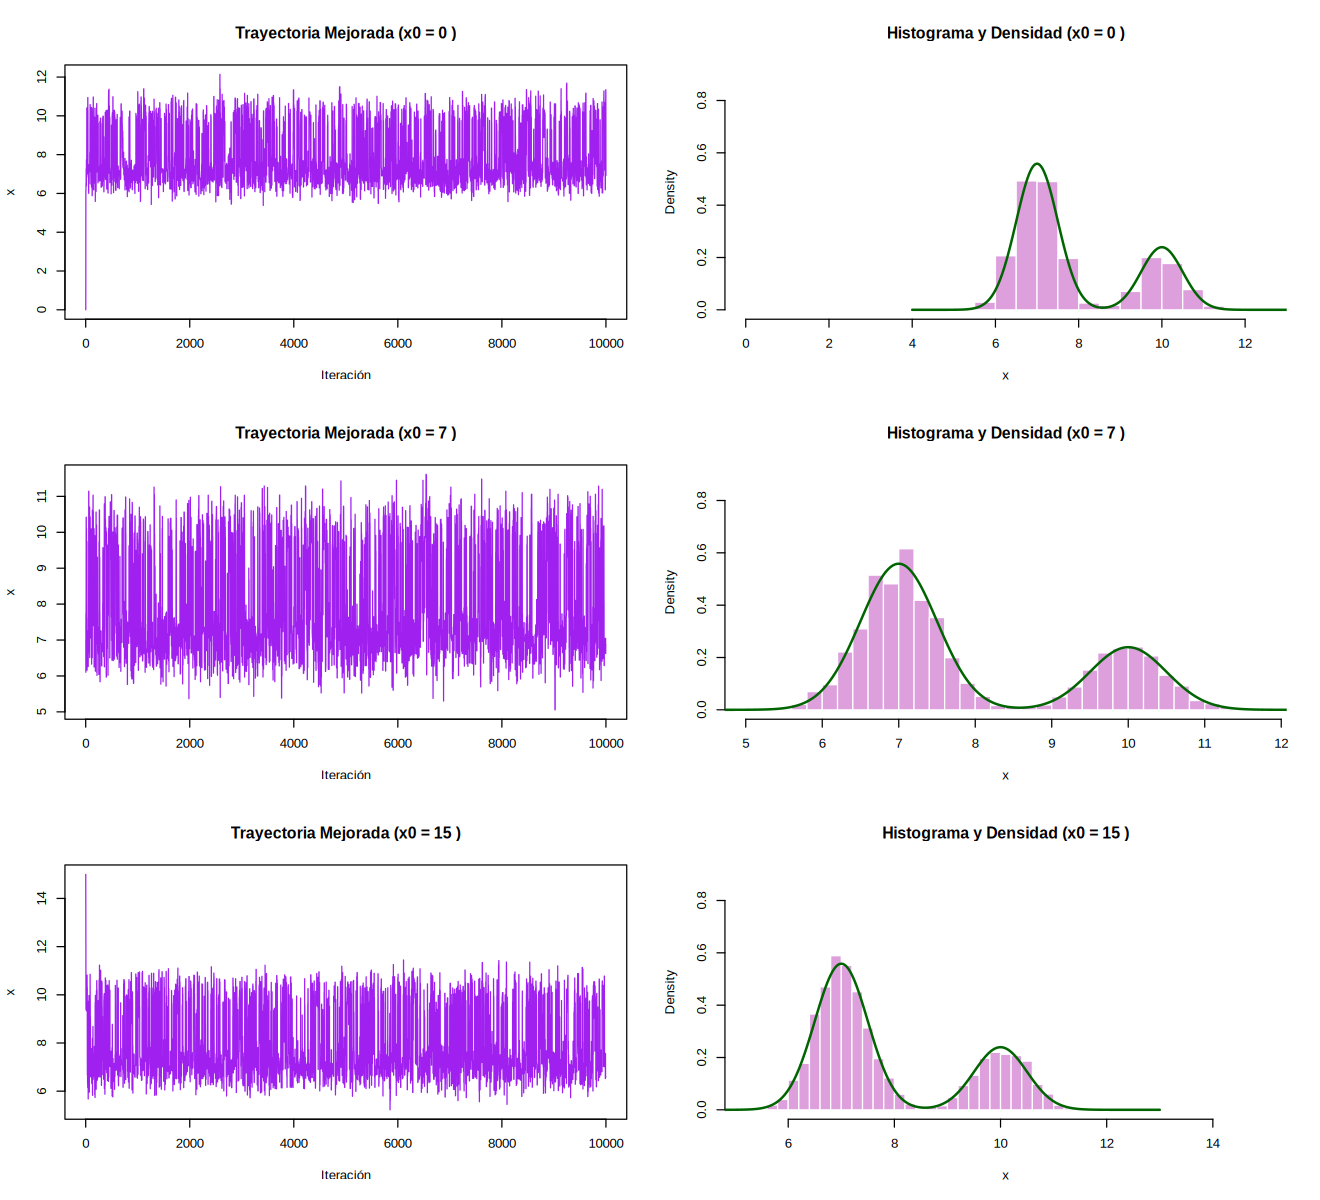

In [123]:
set.seed(777)

densidad_mezcla = function(x) {
  0.7 * dnorm(x, mean = 7, sd = 0.5) + 0.3 * dnorm(x, mean = 10, sd = 0.5)
}

log_densidad_mezcla = function(x) {
  val = densidad_mezcla(x)
  if (val <= 0) return(-Inf)
  log(val)
}

# 2. Parámetros actualizados con una propuesta de mayor varianza (sd = 2.0)
N = 10000
sigma_prop_mejorada = 2.0
valores_iniciales = c(0, 7, 15)

options(repr.plot.width = 11, repr.plot.height = 10, repr.plot.res = 120)
par(mfrow = c(3, 2))

resultados_b = list()

for (i in 1:length(valores_iniciales)) {
  x0 = valores_iniciales[i]
  cadena = numeric(N)
  cadena[1] = x0
  aceptados = 0

  for (t in 1:(N - 1)) {
    x_prop = rnorm(1, mean = cadena[t], sd = sigma_prop_mejorada)

    log_alpha = log_densidad_mezcla(x_prop) - log_densidad_mezcla(cadena[t])

    if (log(runif(1)) < log_alpha) {
      cadena[t + 1] = x_prop
      aceptados = aceptados + 1
    } else {
      cadena[t + 1] = cadena[t]
    }
  }

  resultados_b[[i]] = cadena

  plot(cadena, type = "l", col = "purple",
       main = paste("Trayectoria Mejorada (x0 =", x0, ")"),
       xlab = "Iteración", ylab = "x")

  hist(cadena, breaks = 40, probability = TRUE, col = "plum", border = "white",
       main = paste("Histograma y Densidad (x0 =", x0, ")"),
       xlab = "x", ylim = c(0, 0.9))

  grid_x = seq(4, 13, length.out = 300)
  lines(grid_x, densidad_mezcla(grid_x), col = "darkgreen", lwd = 2)
}

par(mfrow = c(1, 1))

* *A diferencia de la parte (a), al usar una desviación estándar propuesta más amplia ($\text{sd} = 2.0$), las cadenas que inician en $x^{(0)} = 0$ o $x^{(0)} = 15$ logran corregir rápidamente su rumbo inicial (transitorio corto) y convergen con éxito a la región central de la distribución.*

### Conclusiones

* *El impacto crítico de la varianza en las propuestas de caminata aleatoria:
Al implementar el algoritmo de Metropolis-Hastings con una varianza propuesta minúscula ($\sigma_q^2 = 0.01$), comprobé que los saltos se vuelven microscópicos. Esto provoca que las cadenas queden atrapadas permanentemente en el primer modo que encuentran sin poder cruzar el valle de baja probabilidad, lo que demuestra que una propuesta con poca dispersión destruye por completo la capacidad de exploración global del espacio.*

* *Los resultados de las tres cadenas con diferentes puntos de partida ($x^{(0)} = 0, 7, 15$) evidencian que, con una mala elección de la propuesta, la cadena no es ergódica en la práctica. Si el punto inicial está lejos, la simulación se sesga severamente hacia un solo componente de la mezcla, fallando en reflejar la verdadera naturaleza bimodal de la distribución objetivo.*